# HDB Resale Price Pressure in Singapore

**Name:** Thant Eaindray  
**Module:** EP0302 Programming for Data Science  
**Assignment:** CA2 HDB Resale Price Pressure Study  

**Topic Statement:**  
This project investigates which HDB resale flat types and towns show the strongest price pressure in Singapore, and how these patterns may be related to resale demand and HDB flat supply.

## 1. Introduction

Housing affordability is an important issue in Singapore because many households rely on HDB flats as their main form of housing. In recent years, resale flat prices have attracted public attention, especially when prices differ greatly across towns, flat types, and flat sizes.

This study focuses on the HDB resale market in Singapore. It aims to identify which flat types and towns show stronger price pressure, and to examine whether resale demand and HDB flat supply patterns help explain these differences.

The main stakeholder for this analysis is a young Singaporean household planning to buy a resale flat. The findings may help buyers compare towns and flat types more carefully, instead of looking only at the total resale price.

## 2. Dataset Sources

This project uses four official datasets from data.gov.sg. The datasets were selected because they are related to Singapore's HDB resale market and allow the analysis to compare resale prices, resale demand, official median prices, and HDB flat supply.

| No. | Dataset | Agency | Purpose in This Study | URL |
|---|---|---|---|---|
| 1 | Resale Flat Prices from Jan 2017 onwards | HDB | Main transaction-level dataset used to analyse resale prices by town, flat type, floor area, storey range, and lease information. | https://data.gov.sg/datasets/d_8b84c4ee58e3cfc0ece0d773c8ca6abc/view |
| 2 | Number of Resale Applications Registered by Flat Type | HDB | Used as a demand dataset to compare resale application volume across flat types and quarters. | https://data.gov.sg/datasets/d_02aa4bb51bc674f3a2d0b9bb6911d934/view |
| 3 | Median Resale Prices for Registered Applications by Town and Flat Type | HDB | Used as an official summary dataset to compare median resale prices across towns and flat types. | https://data.gov.sg/datasets/d_b51323a474ba789fb4cc3db58a3116d4/view |
| 4 | Dwelling Units under HDB's Management by Town and Flat Type | HDB | Used as a supply dataset to analyse the number of HDB dwelling units by town, flat type, and sold/rental status. | https://data.gov.sg/datasets/d_07b1eeeb22efdf7faf5bd6a13667359d/view |

**Code explanation:**  
- I used this code to check that my CSV files are inside the `Datasets` folder.
- `os.listdir()` returns the file names in the folder.
- The loop prints each file name one by one so I can confirm the files are there before loading them.

In [1]:
import os

dataset_folder = "Datasets"

for file in os.listdir(dataset_folder):
    print(file)

DwellingUnitsunderHDBsManagementbyTownandFlatType.csv
MedianResalePricesforRegisteredApplicationsbyTownandFlatType.csv
NumberofResaleApplicationsRegisteredbyFlatType.csv
ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv


## 3. Import Libraries and Load Datasets

The following code imports the Python libraries needed for data analysis and visualisation. The CSV files are loaded into Pandas DataFrames so that they can be inspected, cleaned, summarised, and visualised.

pd.read_csv() reads each CSV file into a Pandas DataFrame, which works like a table. .shape shows the number of rows and columns, so I can confirm that each dataset loaded correctly.

**Code explanation:**  
- I imported Pandas for working with tables, NumPy for numerical calculations, and Matplotlib/Seaborn for visualisation.
- `sns.set_theme(style="whitegrid")` sets the chart style to a clean white background with grid lines, which makes the charts easier to read.
- `pd.set_option("display.max_columns", None)` tells Pandas to show all columns when displaying a DataFrame, instead of hiding some columns.
- `Path("Datasets")` helps me refer to the dataset folder cleanly.
- `pd.read_csv()` loads each CSV file into a Pandas DataFrame.
- `.shape` shows the number of rows and columns, so I can confirm the datasets loaded correctly.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

dataset_folder = Path("Datasets")

resale_prices = pd.read_csv(dataset_folder / "ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv")
resale_applications = pd.read_csv(dataset_folder / "NumberofResaleApplicationsRegisteredbyFlatType.csv")
median_prices = pd.read_csv(dataset_folder / "MedianResalePricesforRegisteredApplicationsbyTownandFlatType.csv")
dwelling_units = pd.read_csv(dataset_folder / "DwellingUnitsunderHDBsManagementbyTownandFlatType.csv")

print("Resale prices:", resale_prices.shape)
print("Resale applications:", resale_applications.shape)
print("Median prices:", median_prices.shape)
print("Dwelling units:", dwelling_units.shape)

Resale prices: (236719, 11)
Resale applications: (462, 3)
Median prices: (11856, 4)
Dwelling units: (4940, 5)


The four datasets were successfully loaded into Pandas DataFrames. The shape output shows the number of rows and columns in each dataset, which helps confirm that the files were loaded correctly before further inspection and cleaning.

## 4. Initial Dataset Inspection

Before cleaning and analysing the data, each dataset is inspected to understand its structure, column names, data types, missing values, and duplicate rows. This helps identify what preparation is needed before producing summary statistics and visualisations.

This code stores the four DataFrames in a dictionary so I can inspect them using one loop instead of repeating the same code four times. For each dataset, I check the shape, columns, data types, missing values, duplicates, and first few rows. This helps me decide what cleaning is needed.

**Code explanation:**  
- I stored the four DataFrames in a dictionary so I can inspect them using one loop.
- For each dataset, I checked the shape, column names, data types, missing values, duplicate rows, and first five rows.
- This is part of Exploratory Data Analysis because it helps me know what cleaning is needed before I create charts or draw conclusions.
- df.columns.tolist() -> converts the index of column names from a Pandas DataFrame into a standard Python list of strings.
- df.shape -> prints the dimensions of the dataset
- df.dtypes -> shows what type of data is in each column
- .head() -> shows the first few rows
- .shape -> shows number of rows and columns
- .info() -> shows column names, data types, and missing values
- .describe() -> shows summary statistics
- .isna().sum() -> counts missing values
- .duplicated().sum() -> counts duplicate rows

In [3]:
datasets = {
    "Resale Prices": resale_prices,
    "Resale Applications": resale_applications,
    "Median Prices": median_prices,
    "Dwelling Units": dwelling_units
}

for name, df in datasets.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print("Shape:", df.shape)
    print("\nColumn names:")
    print(df.columns.tolist())
    print("\nData types:")
    print(df.dtypes)
    print("\nMissing values:")
    print(df.isna().sum())
    print("\nDuplicate rows:", df.duplicated().sum())
    print("\nFirst 5 rows:")
    display(df.head())

Resale Prices
Shape: (236719, 11)

Column names:
['month', 'town', 'flat_type', 'block', 'street_name', 'storey_range', 'floor_area_sqm', 'flat_model', 'lease_commence_date', 'remaining_lease', 'resale_price']

Data types:
month                      str
town                       str
flat_type                  str
block                      str
street_name                str
storey_range               str
floor_area_sqm         float64
flat_model                 str
lease_commence_date      int64
remaining_lease            str
resale_price           float64
dtype: object

Missing values:
month                  0
town                   0
flat_type              0
block                  0
street_name            0
storey_range           0
floor_area_sqm         0
flat_model             0
lease_commence_date    0
remaining_lease        0
resale_price           0
dtype: int64

Duplicate rows: 316

First 5 rows:


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979,61 years 04 months,232000.0
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978,60 years 07 months,250000.0
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,262000.0
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980,62 years 01 month,265000.0
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,265000.0


Resale Applications
Shape: (462, 3)

Column names:
['quarter', 'flat_type', 'no_of_resale_applications']

Data types:
quarter                        str
flat_type                      str
no_of_resale_applications    int64
dtype: object

Missing values:
quarter                      0
flat_type                    0
no_of_resale_applications    0
dtype: int64

Duplicate rows: 0

First 5 rows:


,quarter,flat_type,no_of_resale_applications
0,2007-Q1,1-room,5
1,2007-Q1,2-room,67
2,2007-Q1,3-room,1908
3,2007-Q1,4-room,2365
4,2007-Q1,5-room,1402


Median Prices
Shape: (11856, 4)

Column names:
['quarter', 'town', 'flat_type', 'price']

Data types:
quarter      str
town         str
flat_type    str
price        str
dtype: object

Missing values:
quarter        0
town           0
flat_type      0
price        456
dtype: int64

Duplicate rows: 0

First 5 rows:


,quarter,town,flat_type,price
0,2007-Q2,Ang Mo Kio,1-room,na
1,2007-Q2,Ang Mo Kio,2-room,-
2,2007-Q2,Ang Mo Kio,3-room,172000
3,2007-Q2,Ang Mo Kio,4-room,260000
4,2007-Q2,Ang Mo Kio,5-room,372000


Dwelling Units
Shape: (4940, 5)

Column names:
['financial_year', 'town_or_estate', 'flat_type', 'sold_or_rental', 'no_of_dwelling_units']

Data types:
financial_year          int64
town_or_estate            str
flat_type                 str
sold_or_rental            str
no_of_dwelling_units      str
dtype: object

Missing values:
financial_year          0
town_or_estate          0
flat_type               0
sold_or_rental          0
no_of_dwelling_units    0
dtype: int64

Duplicate rows: 0

First 5 rows:


,financial_year,town_or_estate,flat_type,sold_or_rental,no_of_dwelling_units
0,2008,Ang Mo Kio,1-room,Rental Units,1318
1,2008,Ang Mo Kio,1-room,Sold Units,0
2,2008,Ang Mo Kio,2-room,Rental Units,2860
3,2008,Ang Mo Kio,2-room,Sold Units,633
4,2008,Ang Mo Kio,3-room,Rental Units,62


### 4.1 Initial Inspection Findings

The resale prices dataset is the main dataset for this project. It contains 236,719 rows and 11 columns, including transaction month, town, flat type, floor area, remaining lease, and resale price. The `month` column is currently stored as text, so it needs to be converted into a date format. There are 316 duplicate rows, but these will not be removed immediately because the dataset does not include a unique transaction ID or unit number. Some rows may look identical because different flats can have the same town, block, storey range, floor area, model, lease, and resale price.

The resale applications dataset contains 462 rows and 3 columns. It records the number of resale applications by quarter and flat type. There are no missing values or duplicate rows. This dataset will be used as a demand indicator.

The median prices dataset contains 11,856 rows and 4 columns. The `price` column is currently stored as text and contains missing or non-numeric values such as `na` and `-`. This column needs to be cleaned and converted into a numeric format before analysis.

The dwelling units dataset contains 4,940 rows and 5 columns. The `no_of_dwelling_units` column is currently stored as text, so it needs to be converted into a numeric format. This dataset will be used to examine HDB flat supply by town, flat type, and sold/rental status.

**Summary of Findings:**
I inspected all four datasets before cleaning. The main issues were date conversion in the resale prices dataset, text-based price values in the median prices dataset, and text-based dwelling unit counts in the supply dataset. I also found 316 duplicate-looking resale rows, but I did not remove them because there was no unique transaction ID. Pandas detected 316 rows with identical values, but I treated them as duplicate-looking rather than confirmed duplicates. Since the dataset does not have a unique transaction ID or unit number, I cannot be sure they are accidental duplicates. They may represent separate flats with the same recorded details, so I kept them to avoid removing valid transactions.

## 5. Data Cleaning and Feature Engineering

The datasets need to be cleaned before analysis. This includes converting date columns, converting numeric columns stored as text, standardising text values, and creating new columns that help answer the research questions.

In [4]:
# Create cleaned copies so the original datasets remain unchanged
resale_clean = resale_prices.copy()
applications_clean = resale_applications.copy()
median_clean = median_prices.copy()
dwelling_clean = dwelling_units.copy()

# Function to standardise flat type values across datasets
def clean_flat_type(value):
    value = str(value).strip().lower().replace("-", " ")
    return value.title()

# Clean resale prices dataset
resale_clean["month"] = pd.to_datetime(resale_clean["month"])
resale_clean["year"] = resale_clean["month"].dt.year
resale_clean["quarter"] = (
    resale_clean["month"].dt.year.astype(str)
    + "-Q"
    + resale_clean["month"].dt.quarter.astype(str)
)

resale_clean["price_per_sqm"] = resale_clean["resale_price"] / resale_clean["floor_area_sqm"]

resale_clean["town"] = resale_clean["town"].str.title()
resale_clean["flat_type"] = resale_clean["flat_type"].apply(clean_flat_type)

# Clean resale applications dataset
applications_clean["flat_type"] = applications_clean["flat_type"].apply(clean_flat_type)

# Clean median prices dataset
median_clean["town"] = median_clean["town"].str.title()
median_clean["flat_type"] = median_clean["flat_type"].apply(clean_flat_type)
median_clean["price"] = median_clean["price"].replace(["na", "NA", "-"], np.nan)
median_clean["price"] = pd.to_numeric(median_clean["price"], errors="coerce")

# Clean dwelling units dataset
dwelling_clean["town_or_estate"] = dwelling_clean["town_or_estate"].str.title()
dwelling_clean["flat_type"] = dwelling_clean["flat_type"].apply(clean_flat_type)
dwelling_clean["no_of_dwelling_units"] = pd.to_numeric(
    dwelling_clean["no_of_dwelling_units"], errors="coerce"
)

print("Cleaning completed.")
print("Resale prices:", resale_clean.shape)
print("Applications:", applications_clean.shape)
print("Median prices:", median_clean.shape)
print("Dwelling units:", dwelling_clean.shape)

Cleaning completed.
Resale prices: (236719, 14)
Applications: (462, 3)
Median prices: (11856, 4)
Dwelling units: (4940, 5)


**Code explanation:**  
- I created cleaned copies of the original datasets using `.copy()` so that the raw imported data remains unchanged. This is useful because if I make a mistake during cleaning, I can still refer back to the original data.

- I created a function called `clean_flat_type()` to standardise flat type values across the datasets. This is needed because different datasets write flat types differently, such as `2 ROOM` in one dataset and `2-room` in another dataset. The function converts the value to text, removes extra spaces, changes it to lowercase, replaces hyphens with spaces, and then changes it to title case. For example, both `2 ROOM` and `2-room` become `2 Room`.

- I converted the `month` column in the resale prices dataset into a proper date format using `pd.to_datetime()`. This allows me to extract the `year` and `quarter` from the date.

- I created the `year` column so I can analyse resale price trends by year. I created the `quarter` column because the resale applications dataset is organised by quarter, so I need the same quarter format in the resale price dataset before merging them later.

- The `quarter` column creates values such as `2017-Q1`, `2017-Q2`, and `2026-Q1`. A quarter means a three-month period. For example, Q1 is January to March, Q2 is April to June, Q3 is July to September, and Q4 is October to December.

- I created `price_per_sqm` by dividing `resale_price` by `floor_area_sqm`. This is important because total resale price can be affected by flat size. Price per square metre gives a fairer comparison between flats of different sizes.

- I standardised town names using `.str.title()` so the town names have a cleaner and more consistent format.

- I applied `clean_flat_type()` to the flat type columns in all relevant datasets so that flat type names match across datasets. This is important because I later group and merge data by flat type.

- In the median resale prices dataset, the `price` column was stored as text and contained non-numeric values like `na`, `NA`, and `-`. I replaced those values with `np.nan`, which represents missing values.

- I then used `pd.to_numeric()` to convert the median `price` column into numeric format so calculations can be done properly.

- I used `errors="coerce"` when converting values to numeric. This means if Pandas cannot convert a value into a number, it will turn it into `NaN` instead of causing an error.

- In the dwelling units dataset, I converted `no_of_dwelling_units` into numeric format because it was stored as text. This is needed because I later calculate total sold HDB dwelling units by town and flat type.

- Finally, I printed the shape of each cleaned dataset to check that cleaning was completed and that the datasets still have the expected number of rows and columns.

The code creates cleaned copies of the datasets so the original imported data is preserved. The resale `month` column is converted into a date format so that `year` and `quarter` can be extracted. A new column called `price_per_sqm` is created because total resale price is affected by flat size, so price per square metre gives a fairer comparison between different flats.

Text values such as town names and flat types are also standardised. This is important because the same flat type may be written differently across datasets, such as `2 ROOM` in one dataset and `2-room` in another dataset.

### 5.1 Verification After Cleaning

After cleaning, the datasets are checked again to confirm that date and numeric conversions were successful, and that flat type values are standardised across datasets.

In [5]:
print("Resale prices data types:")
print(resale_clean[["month", "year", "quarter", "floor_area_sqm", "resale_price", "price_per_sqm"]].dtypes)

print("\nMedian prices data types:")
print(median_clean[["quarter", "town", "flat_type", "price"]].dtypes)

print("\nDwelling units data types:")
print(dwelling_clean[["financial_year", "town_or_estate", "flat_type", "sold_or_rental", "no_of_dwelling_units"]].dtypes)

print("\nFlat types in resale prices:")
print(sorted(resale_clean["flat_type"].unique()))

print("\nFlat types in resale applications:")
print(sorted(applications_clean["flat_type"].unique()))

print("\nFlat types in median prices:")
print(sorted(median_clean["flat_type"].unique()))

print("\nFlat types in dwelling units:")
print(sorted(dwelling_clean["flat_type"].unique()))

print("\nMissing values after cleaning:")
print("Resale price_per_sqm:", resale_clean["price_per_sqm"].isna().sum())
print("Median price:", median_clean["price"].isna().sum())
print("Dwelling units:", dwelling_clean["no_of_dwelling_units"].isna().sum())

Resale prices data types:
month             datetime64[us]
year                       int32
quarter                      str
floor_area_sqm           float64
resale_price             float64
price_per_sqm            float64
dtype: object

Median prices data types:
quarter          str
town             str
flat_type        str
price        float64
dtype: object

Dwelling units data types:
financial_year            int64
town_or_estate              str
flat_type                   str
sold_or_rental              str
no_of_dwelling_units    float64
dtype: object

Flat types in resale prices:
['1 Room', '2 Room', '3 Room', '4 Room', '5 Room', 'Executive', 'Multi Generation']

Flat types in resale applications:
['1 Room', '2 Room', '3 Room', '4 Room', '5 Room', 'Executive']

Flat types in median prices:
['1 Room', '2 Room', '3 Room', '4 Room', '5 Room', 'Executive']

Flat types in dwelling units:
['1 Room', '2 Room', '3 Room', '4 Room', '5 Room', 'Executive', 'Hudc', 'Studio Apartment']

Mis

**Code explanation:**  
- This code verifies whether the cleaning steps worked correctly before I start the actual analysis.

- First, I printed the data types for important columns in the resale prices dataset. I checked that `month` became a date column, `year` became a number, and `floor_area_sqm`, `resale_price`, and `price_per_sqm` are numeric. This is important because date and numeric columns are needed for calculations and charts.

- Then, I checked the data types for the median prices dataset. I wanted to make sure the `price` column was successfully converted from text into numeric format, because I cannot calculate median prices properly if the values are still stored as text.

- After that, I checked the data types for the dwelling units dataset. The main column I needed to verify was `no_of_dwelling_units`, because it must be numeric before I can sum the total number of HDB units by town or flat type.

- I also printed the unique flat type values from all four datasets. This helps confirm that the flat type names were standardised properly. This is important because I later group and merge datasets using `flat_type`.

- `sorted()` is used so the flat type values appear in alphabetical order, making them easier to compare.

- `.unique()` shows the different values that appear in a column. For example, it helps me check whether flat types like `2 Room`, `3 Room`, and `4 Room` are written consistently.

- Finally, I checked missing values after cleaning for `price_per_sqm`, median `price`, and `no_of_dwelling_units`.

- The resale `price_per_sqm` column has no missing values, so it is ready for analysis.

- The median `price` column still has missing values because some town and flat type combinations do not have enough resale transactions in certain quarters. I do not treat this as an error. I exclude missing prices only when doing calculations.

- The dwelling units dataset also has some missing values after conversion, so I exclude those missing rows when doing the supply analysis.

The verification shows that the resale `month` column has been converted into a date format, while `resale_price`, `floor_area_sqm`, `price_per_sqm`, median `price`, and `no_of_dwelling_units` are numeric. This means the datasets are ready for statistical calculations and visualisations.

The median resale price dataset still contains missing price values after cleaning. This is expected because some town and flat type combinations may not have enough resale transactions in certain quarters. These missing price values will be excluded only when price calculations are performed.

The dwelling units dataset also contains a small number of missing dwelling unit values after numeric conversion. These rows will be handled during the supply analysis section.

## 6. Research Questions

This project investigates HDB resale price pressure in Singapore using resale transaction prices, resale demand, official median prices, and HDB dwelling unit supply.

The analysis will answer the following research questions:

1. Which HDB flat types experienced the strongest resale price growth from 2017 to 2026?
2. Which towns have the highest resale prices and highest price per square metre?
3. How does resale demand differ across flat types, and does it move together with resale price trends?
4. How does HDB flat supply differ across towns and flat types, and what might this suggest about price pressure?

For my research questions, I wanted to study HDB resale price pressure from a few angles, not just price alone.

First, I looked at flat types to see which type had the strongest price growth over time. Then I looked at towns to compare which areas had higher resale prices and higher price per square metre. After that, I looked at resale applications as a demand indicator to see whether demand moves together with price trends. Lastly, I looked at HDB dwelling unit supply to see whether supply patterns might help explain price pressure.

So overall, my four questions cover price, location, demand, and supply.

## 7. Analysis Question 1: Which HDB Flat Types Experienced the Strongest Resale Price Growth?

This section analyses resale price trends by flat type from 2017 to the latest available year in the dataset. Median resale price is used instead of mean resale price because property prices can be affected by very expensive outlier transactions.

In [6]:
# Calculate yearly median resale price by flat type
yearly_flat_type_prices = (
    resale_clean
    .groupby(["year", "flat_type"])
    .agg(
        transaction_count=("resale_price", "count"),
        median_resale_price=("resale_price", "median"),
        mean_resale_price=("resale_price", "mean"),
        price_std_dev=("resale_price", lambda x: np.std(x, ddof=1))
    )
    .reset_index()
)

yearly_flat_type_prices.head(10)

,year,flat_type,transaction_count,median_resale_price,mean_resale_price,price_std_dev
0,2017,1 Room,9,203000.0,200888.888889,13986.104215
1,2017,2 Room,219,240000.0,240354.219178,29594.704995
2,2017,3 Room,5047,301888.0,317834.236156,69948.747158
3,2017,4 Room,8604,408000.0,437119.995337,114519.806567
4,2017,5 Room,5002,478000.0,532276.723239,149279.257398
5,2017,Executive,1624,600000.0,627211.265394,118286.991990
6,2017,Multi Generation,4,765000.0,783750.000000,104831.213545
7,2018,1 Room,9,180000.0,184111.111111,19186.221908
8,2018,2 Room,286,230000.0,235763.398601,39993.490835
9,2018,3 Room,5119,290000.0,306477.979879,71800.682628


**Code explanation:**  
For Question 1, I used the cleaned resale prices dataset to analyse how resale prices changed by flat type from 2017 to 2026. I focused mainly on median resale price instead of mean resale price because property prices can have outliers, such as unusually expensive flats. Median is less affected by these extreme values, so it gives a better idea of the typical resale price.

In this code, I grouped the data by `year` and `flat_type`. This means Pandas separates the resale transactions into groups such as 2017 3 Room flats, 2017 4 Room flats, 2018 3 Room flats, and so on. This allows me to compare each flat type across different years.

For each year and flat type group, I calculated four summary values. 
- `transaction_count` counts how many resale transactions there are in that group. 
- `median_resale_price` calculates the middle resale price, which is the main value I use for the analysis. 
- `mean_resale_price` calculates the average resale price, which is included as an additional summary. 
- `price_std_dev` calculates the standard deviation using NumPy, which shows how spread out the resale prices are within that group.

**Why use?**
- The `lambda x` part is a small temporary function. In this case, `x` represents the resale prices inside each year and flat type group, and 
- `np.std(x, ddof=1)` calculates the standard deviation for that group. I used `ddof=1` to calculate sample standard deviation. Since the dataset is a sample of transactions grouped by year and flat type, this is a suitable setting.

After the grouping and calculations, I used `reset_index()` to convert the grouped result back into a normal DataFrame. This makes the table easier to display, use, and plot later. Finally, I used `head(10)` to preview the first 10 rows and check that the summary table looks correct.

Overall, this code prepares the yearly flat type price summary that I use for the line chart and price growth analysis.

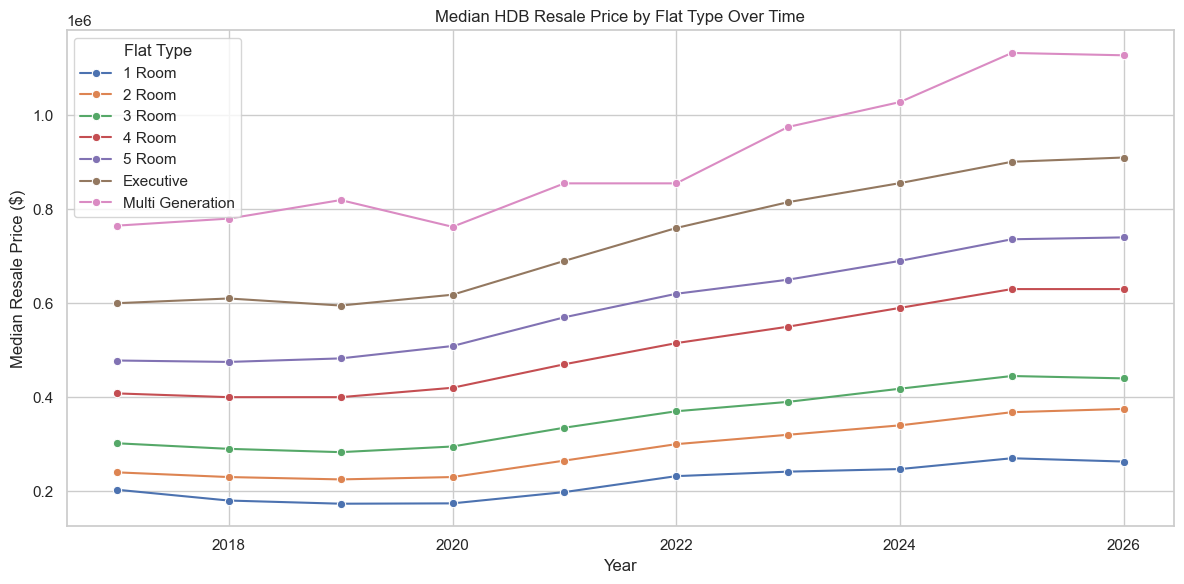

In [7]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_flat_type_prices,
    x="year",
    y="median_resale_price",
    hue="flat_type",
    marker="o"
)

plt.title("Median HDB Resale Price by Flat Type Over Time")
plt.xlabel("Year")
plt.ylabel("Median Resale Price ($)")
plt.legend(title="Flat Type")
plt.tight_layout()
plt.show()

**Code explanation:**  
This code creates a line chart to show how median HDB resale prices changed over time for each flat type.

I used `plt.figure(figsize=(12, 6))` to set the chart size. The width is 12 and the height is 6, so the chart is wide enough to show the yearly trend clearly.

I used `sns.lineplot()` because a line chart is suitable for showing changes over time. The dataset used is `yearly_flat_type_prices`, which already contains the yearly summary of median resale prices by flat type.

The x-axis is `year`, so the chart shows the time period from 2017 to 2026. The y-axis is `median_resale_price`, which shows the typical resale price for each flat type in each year.

I used `hue="flat_type"` so that each flat type has its own coloured line. This makes it easier to compare price trends between flat types, such as 3 Room, 4 Room, 5 Room, and Executive flats.

I used `marker="o"` to show the actual yearly data points on each line. This makes it easier to see the value for each year instead of only seeing the line trend.

The title, x-axis label, y-axis label, and legend are added to make the chart easier to understand. `plt.tight_layout()` adjusts the spacing so the labels and legend do not overlap, and `plt.show()` displays the chart.

In [8]:
first_year = yearly_flat_type_prices["year"].min()
latest_year = yearly_flat_type_prices["year"].max()

price_growth = yearly_flat_type_prices.pivot(
    index="flat_type",
    columns="year",
    values="median_resale_price"
)

price_growth["price_growth"] = price_growth[latest_year] - price_growth[first_year]
price_growth["percentage_growth"] = (
    price_growth["price_growth"] / price_growth[first_year] * 100
)

price_growth_summary = (
    price_growth[[first_year, latest_year, "price_growth", "percentage_growth"]]
    .sort_values("percentage_growth", ascending=False)
    .round(2)
)

price_growth_summary

year,2017,2026,price_growth,percentage_growth
flat_type,,,,
2 Room,240000.0,375000.0,135000.0,56.25
5 Room,478000.0,740000.0,262000.0,54.81
4 Room,408000.0,630000.0,222000.0,54.41
Executive,600000.0,910000.0,310000.0,51.67
Multi Generation,765000.0,1127500.0,362500.0,47.39
3 Room,301888.0,440000.0,138112.0,45.75
1 Room,203000.0,263000.0,60000.0,29.56


**Code explanation:**  
This code calculates how much the median resale price increased for each flat type from the first year to the latest year in the dataset.

First, `first_year` finds the earliest year in `yearly_flat_type_prices`, and `latest_year` finds the latest year. In my dataset, this compares 2017 with 2026.

Next, I used `pivot()` to reshape the summary table. Before pivoting, each row contains one year and one flat type. After pivoting, each flat type becomes a row, and each year becomes a column. The values inside the table are the median resale prices. This makes it easier to compare the median price in 2017 against the median price in 2026 for each flat type.

Then, I created a new column called `price_growth`. This subtracts the median resale price in the first year from the median resale price in the latest year. It shows the actual dollar increase for each flat type.

I also created `percentage_growth`, which divides the dollar increase by the first year’s median price and multiplies by 100. This shows the growth as a percentage, which is useful because different flat types started at different price levels.

After that, I selected only the important columns: the first year price, the latest year price, dollar growth, and percentage growth. I sorted the table by `percentage_growth` in descending order so the flat type with the strongest percentage increase appears at the top.

Finally, I used `.round(2)` to round the numbers to two decimal places, making the output easier to read.

groupby(["year", "flat_type"]) groups the resale transactions by year and flat type. Then agg() calculates the number of transactions, median price, mean price, and standard deviation. I used NumPy’s np.std() to calculate the standard deviation, which shows how spread out prices are within each flat type.
The line chart is suitable because it shows how median resale prices changed over time. The percentage growth table compares the earliest year with the latest available year to identify which flat types increased the most.

### 7.1 Key Insights for Question 1

- All HDB flat types had higher median resale prices from 2017 to 2026, showing a general upward price trend.

- In percentage terms, **2 Room flats had the strongest growth**, increasing from **$240,000 in 2017** to **$375,000 in 2026**, which is a **56.25% increase**.

- In dollar terms, **Multi Generation flats had the largest increase**, rising from **$765,000** to **$1,127,500**, an increase of **$362,500**.

- Percentage growth and dollar growth tell different stories. Smaller flats can show higher percentage growth because they start from a lower price, while larger flats can show bigger dollar increases because their prices are already higher.

- This suggests that resale price pressure affects both smaller and larger flat types, not only expensive flat categories.

- One limitation is that **2026 may be partial-year data**, so comparisons involving 2026 should be interpreted carefully.

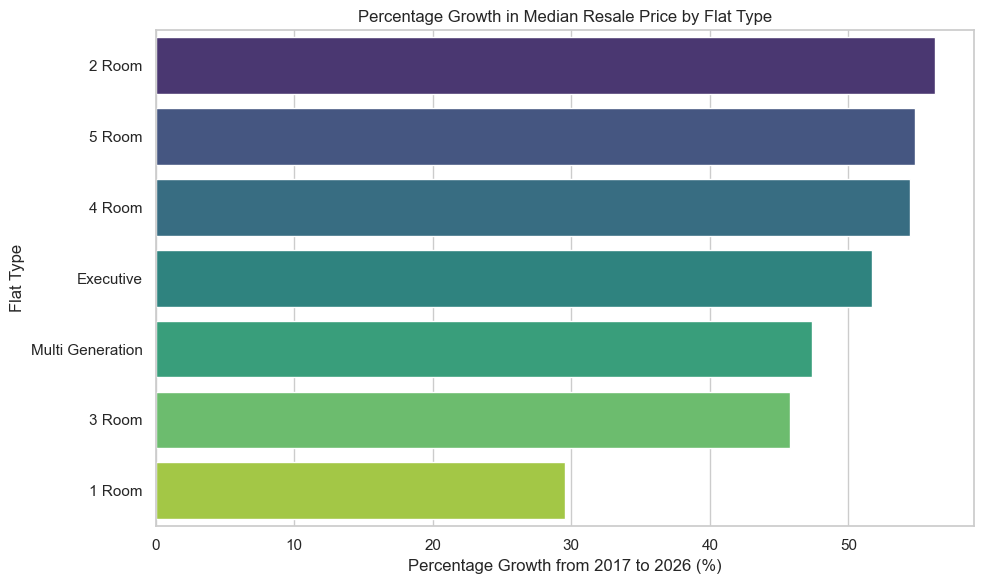

In [9]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=price_growth_summary.reset_index(),
    x="percentage_growth",
    y="flat_type",
    hue="flat_type",
    palette="viridis",
    legend=False
)

plt.title("Percentage Growth in Median Resale Price by Flat Type")
plt.xlabel("Percentage Growth from 2017 to 2026 (%)")
plt.ylabel("Flat Type")
plt.tight_layout()
plt.show()

**Code explanation:**  
This code creates a bar chart to compare the percentage growth in median resale price for each flat type from 2017 to 2026.

I used `price_growth_summary` as the data because it already contains the calculated percentage growth for each flat type. I used `.reset_index()` because `flat_type` was stored as the index in the summary table, and resetting the index turns it back into a normal column that Seaborn can use for plotting.

The x-axis is `percentage_growth`, so it shows how much the median resale price increased in percentage terms. The y-axis is `flat_type`, so each bar represents one HDB flat type.

I used `hue="flat_type"` together with `palette="viridis"` so each flat type has a different colour. I set `legend=False` because the flat type names are already shown on the y-axis, so a legend would be repeated information.

The chart title and axis labels make the chart easier to understand. `plt.tight_layout()` adjusts the spacing so the labels fit nicely, and `plt.show()` displays the chart.

Overall, 2 Room flats had the highest percentage growth.

The line chart shows the trend over time, while the bar chart makes it easier to compare total percentage growth across flat types. I used both because they answer slightly different parts of the question.

## 8. Analysis Question 2: Which Towns Have the Highest Resale Prices and Price per Square Metre?

This section analyses resale prices by town. Both median resale price and median price per square metre are used. Median resale price shows the typical total transaction price, while price per square metre gives a fairer comparison between towns because flats may differ in size.

In [10]:
town_price_summary = (
    resale_clean
    .groupby("town")
    .agg(
        transaction_count=("resale_price", "count"),
        median_resale_price=("resale_price", "median"),
        mean_resale_price=("resale_price", "mean"),
        median_price_per_sqm=("price_per_sqm", "median"),
        mean_price_per_sqm=("price_per_sqm", "mean")
    )
    .sort_values("median_price_per_sqm", ascending=False)
    .round(2)
)

town_price_summary.head(10)

,transaction_count,median_resale_price,mean_resale_price,median_price_per_sqm,mean_price_per_sqm
town,,,,,
Central Area,1837,570000.0,699558.65,7678.57,8319.16
Queenstown,6472,670000.0,648654.25,7502.00,7723.73
Bukit Merah,9032,660000.0,644320.64,6956.52,7318.38
Bukit Timah,576,781500.0,787623.63,6780.82,7096.11
Bishan,4118,696400.0,716197.04,6395.00,6649.06
Marine Parade,1438,490444.0,562594.72,6323.80,6431.78
Kallang/Whampoa,7212,570000.0,599741.66,6257.14,6836.30
Clementi,5245,496888.0,563205.93,5772.36,6447.36
Toa Payoh,7758,510000.0,582149.93,5769.23,6554.17


**Code explanation:**  
This code creates a town-level price summary from the cleaned resale transaction dataset. I grouped the data by `town` so that each row represents one HDB town instead of one individual resale transaction.

For each town, I calculated the number of transactions, the median and mean resale price, and the median and mean price per square metre. The `transaction_count` helps me see how much data each town has, while the median values are more reliable for comparison because resale prices can be affected by very expensive outliers.

I sorted the table by `median_price_per_sqm` in descending order because price per square metre gives a fairer comparison between towns. Total resale price can be higher simply because flats are larger, but price per square metre shows how expensive the location is after adjusting for flat size.

The `.round(2)` makes the results easier to read, and `head(10)` displays the top 10 towns with the highest median price per square metre.

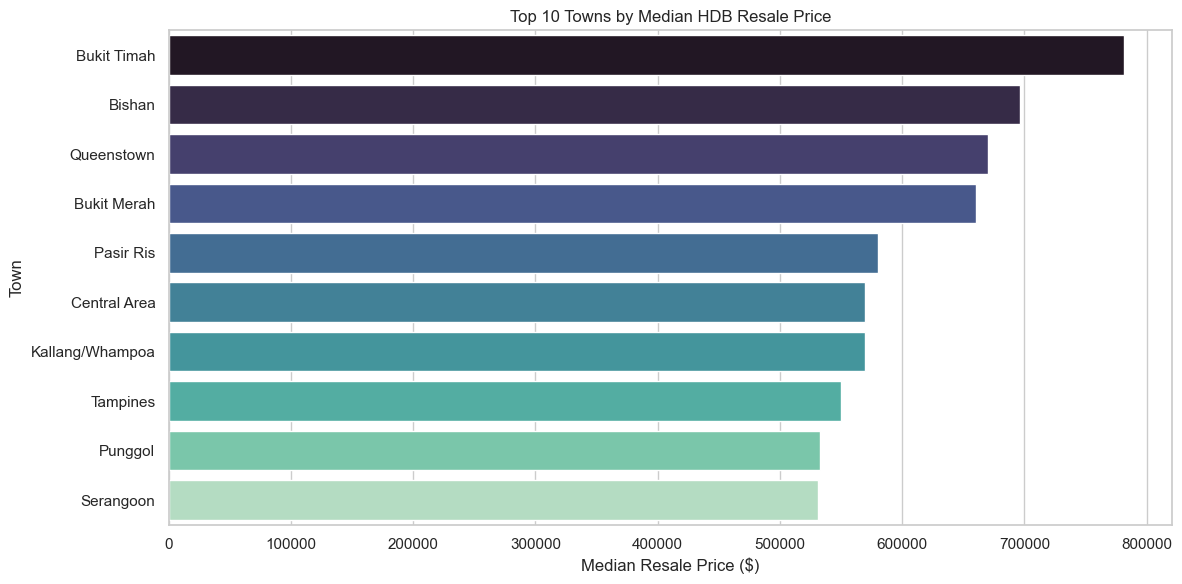

In [11]:
top_towns_by_price = (
    town_price_summary
    .sort_values("median_resale_price", ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_towns_by_price,
    x="median_resale_price",
    y="town",
    hue="town",
    palette="mako",
    legend=False
)

plt.title("Top 10 Towns by Median HDB Resale Price")
plt.xlabel("Median Resale Price ($)")
plt.ylabel("Town")
plt.tight_layout()
plt.show()

**Code explanation:**  
This code visualises the top 10 towns with the highest median HDB resale price. I used `town_price_summary`, which was already grouped by town in the previous step.

First, I sorted the towns by `median_resale_price` in descending order so that the most expensive towns by typical resale price appear at the top. Then I used `.head(10)` to keep only the top 10 towns. I also used `.reset_index()` so that `town` becomes a normal column again, which makes it easier for Seaborn to plot.

The bar chart uses `median_resale_price` on the x-axis and `town` on the y-axis. I used median resale price instead of mean because median is less affected by unusually expensive flats. This chart helps me quickly compare which towns have the highest typical resale prices.

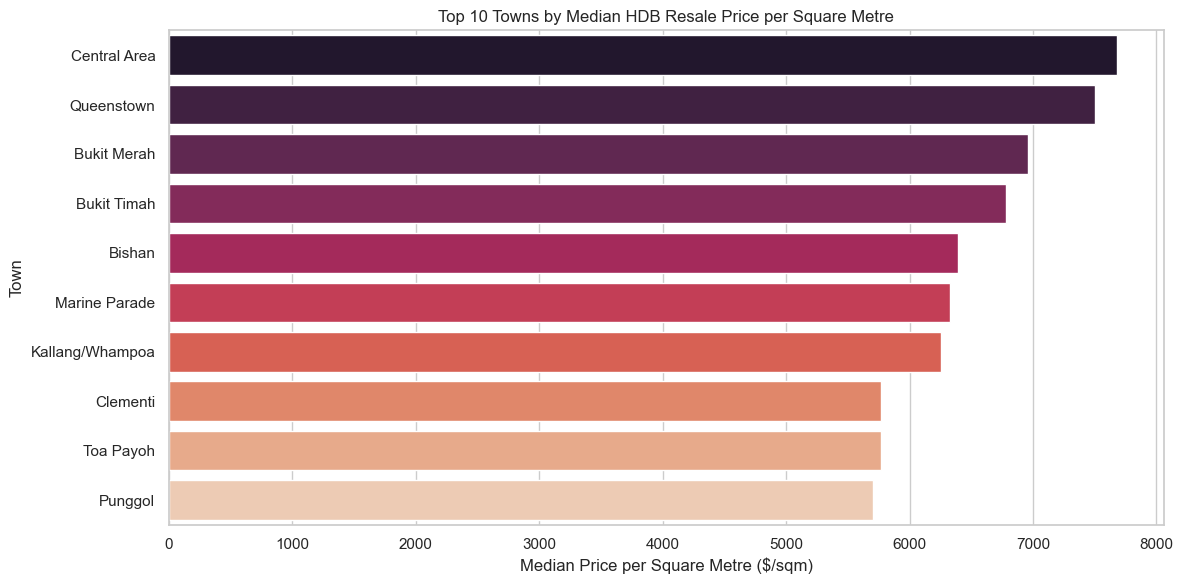

In [12]:
top_towns_by_psm = town_price_summary.head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_towns_by_psm,
    x="median_price_per_sqm",
    y="town",
    hue="town",
    palette="rocket",
    legend=False
)

plt.title("Top 10 Towns by Median HDB Resale Price per Square Metre")
plt.xlabel("Median Price per Square Metre ($/sqm)")
plt.ylabel("Town")
plt.tight_layout()
plt.show()

**Code explanation:**  
This code visualises the top 10 towns with the highest median HDB resale price per square metre. I used `town_price_summary`, which was already sorted by `median_price_per_sqm` from highest to lowest in the previous step, so `.head(10)` gives the top 10 towns.

I used `.reset_index()` to turn `town` back into a normal column so Seaborn can use it for the chart. The bar chart places `median_price_per_sqm` on the x-axis and `town` on the y-axis.

This chart is important because price per square metre gives a fairer comparison between towns. A town may have high total resale prices because its flats are larger, but price per square metre shows which towns are more expensive after adjusting for flat size.

In [13]:
top_towns_comparison = town_price_summary[
    ["transaction_count", "median_resale_price", "median_price_per_sqm"]
].sort_values("median_price_per_sqm", ascending=False).head(10)

top_towns_comparison

,transaction_count,median_resale_price,median_price_per_sqm
town,,,
Central Area,1837,570000.0,7678.57
Queenstown,6472,670000.0,7502.00
Bukit Merah,9032,660000.0,6956.52
Bukit Timah,576,781500.0,6780.82
Bishan,4118,696400.0,6395.00
Marine Parade,1438,490444.0,6323.80
Kallang/Whampoa,7212,570000.0,6257.14
Clementi,5245,496888.0,5772.36
Toa Payoh,7758,510000.0,5769.23


**Code explanation:**

This code creates a smaller comparison table for the top 10 towns by median price per square metre. I selected only the columns that are most useful for explaining the town analysis: `transaction_count`, `median_resale_price`, and `median_price_per_sqm`.

I then sorted the towns by `median_price_per_sqm` in descending order and used `.head(10)` to display the top 10 towns. This table supports the bar chart by showing the actual values behind the visualisation.

The `transaction_count` column is useful because it shows how many resale transactions were used for each town. This helps me judge whether the result is based on many transactions or only a small number of records.

This analysis groups resale transactions by town and calculates median resale price and median price per square metre. Median resale price shows the typical total price paid, while price per square metre adjusts for flat size. This is important because a town may appear expensive simply because it has more large flats, so price per square metre gives a fairer comparison.

### 8.1 Key Insights for Question 2

- The highest price pressure by price per square metre is mainly found in Central Area, Queenstown, Bukit Merah, Bukit Timah, and Bishan.

- Central Area has the highest median price per square metre at about $7,678.57 per sqm, even though its median resale price is $570,000. This suggests that flats there may be smaller but still expensive for their size.

- Queenstown and Bukit Merah also have high price per square metre values, likely because they are mature estates near central areas with good accessibility and amenities.

- Bukit Timah has the highest median resale price at $781,500, but it is not ranked first by price per square metre. This shows why price per square metre is useful because total price and size-adjusted price can give different rankings.

- Punggol is notable because it has both a high transaction count and appears in the top 10 by price per square metre. This suggests price pressure can also appear in newer towns, not only mature estates.

- A limitation is that this analysis does not include factors like MRT distance, floor level, flat age, or remaining lease, which can also affect resale prices.

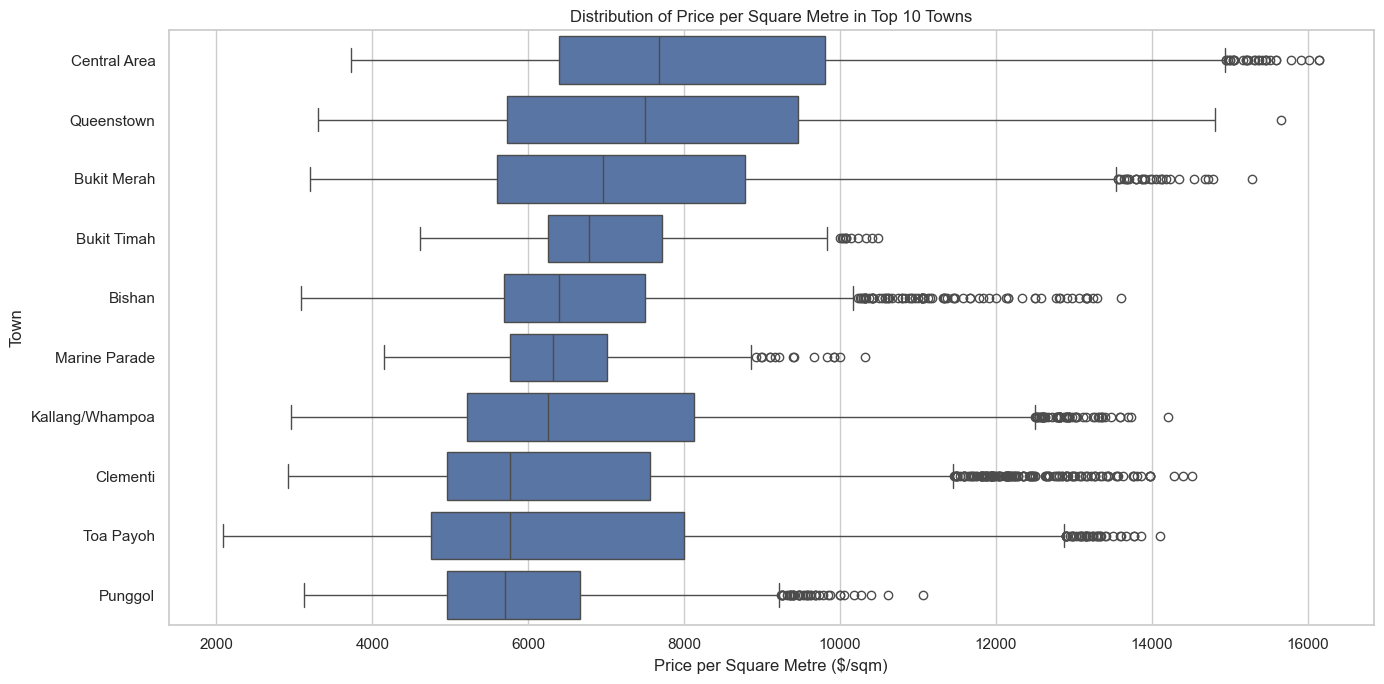

In [14]:
top_10_psm_towns = top_towns_by_psm["town"].tolist()

top_town_transactions = resale_clean[
    resale_clean["town"].isin(top_10_psm_towns)
]

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=top_town_transactions,
    x="price_per_sqm",
    y="town",
    order=top_10_psm_towns
)

plt.title("Distribution of Price per Square Metre in Top 10 Towns")
plt.xlabel("Price per Square Metre ($/sqm)")
plt.ylabel("Town")
plt.tight_layout()
plt.show()

**Code explanation:**

This code creates a boxplot to show the distribution of resale price per square metre for the top 10 towns. First, I used `top_towns_by_psm["town"].tolist()` to store the names of the top 10 towns in a Python list.

Next, I filtered `resale_clean` using `.isin(top_10_psm_towns)` so that the chart only includes transactions from those top 10 towns. This means the boxplot is based on the actual individual resale transactions, not just the summary table.

The boxplot shows how spread out the `price_per_sqm` values are for each town. The line inside each box represents the median, the box shows the middle range of prices, and the points outside the whiskers are possible outliers.

This chart is useful because two towns may have similar median price per square metre, but their price distribution can still be different. It helps me see whether prices in a town are consistent or more varied.

## 9. Analysis Question 3: How Does Resale Demand Differ Across Flat Types, and Does It Move Together with Resale Price Trends?

This section compares resale application volume with resale price trends by flat type. The number of resale applications is used as a demand indicator, while median resale price is used as the price indicator. By combining these datasets, the analysis can examine whether flat types with higher demand also show stronger price movement.

In [15]:
print("Applications earliest quarter:", applications_clean["quarter"].min())
print("Applications latest quarter:", applications_clean["quarter"].max())

applications_clean.head()

Applications earliest quarter: 2007-Q1
Applications latest quarter: 2026-Q1


,quarter,flat_type,no_of_resale_applications
0,2007-Q1,1 Room,5
1,2007-Q1,2 Room,67
2,2007-Q1,3 Room,1908
3,2007-Q1,4 Room,2365
4,2007-Q1,5 Room,1402


**Code explanation:**

This code checks the resale applications dataset before using it for the demand analysis. I printed the earliest and latest `quarter` values to understand the time period covered by this dataset.

This is important because the resale applications dataset is used as a demand indicator, so I need to know whether its date range overlaps with the resale price dataset. If the time periods do not match, the comparison between demand and price would not be reliable.

The `applications_clean.head()` line displays the first few rows of the cleaned applications dataset so I can quickly confirm that the columns and values look correct before continuing with the analysis.

In [16]:
applications_by_flat_type = (
    applications_clean
    .groupby("flat_type")
    .agg(
        total_applications=("no_of_resale_applications", "sum"),
        average_quarterly_applications=("no_of_resale_applications", "mean"),
        max_quarterly_applications=("no_of_resale_applications", "max")
    )
    .sort_values("total_applications", ascending=False)
    .round(2)
)

applications_by_flat_type

,total_applications,average_quarterly_applications,max_quarterly_applications
flat_type,,,
4 Room,196920,2557.40,4062
3 Room,131140,1703.12,3015
5 Room,119044,1546.03,3422
Executive,36763,477.44,1058
2 Room,9205,119.55,256
1 Room,235,3.05,11


**Code explanation:**

This code summarises resale demand by flat type using the resale applications dataset. I grouped the data by `flat_type` so that each row represents one flat type instead of one quarter.

For each flat type, I calculated the total number of resale applications, the average number of applications per quarter, and the maximum number of applications recorded in a quarter. The total applications show overall demand, the average gives a typical quarterly demand level, and the maximum shows the highest demand peak.

I sorted the results by `total_applications` in descending order so that the flat types with the strongest overall resale demand appear first. The `.round(2)` makes the average values easier to read.

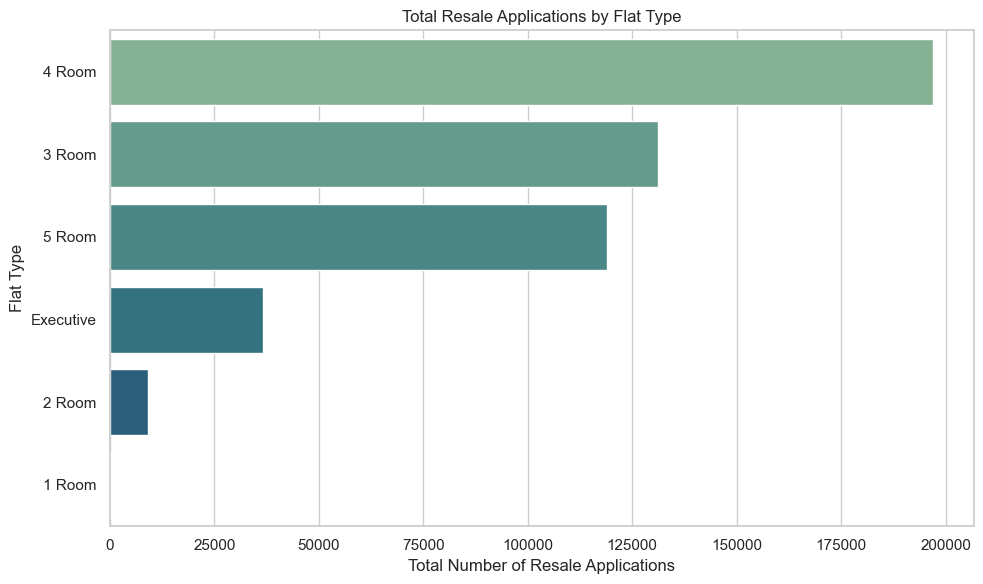

In [17]:
applications_plot = applications_by_flat_type.reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=applications_plot,
    x="total_applications",
    y="flat_type",
    hue="flat_type",
    palette="crest",
    legend=False
)

plt.title("Total Resale Applications by Flat Type")
plt.xlabel("Total Number of Resale Applications")
plt.ylabel("Flat Type")
plt.tight_layout()
plt.show()

**Code explanation:**

This code creates a bar chart to compare total resale applications across flat types. I used `applications_by_flat_type`, which was already grouped and summarised in the previous step.

I used `.reset_index()` to turn `flat_type` back into a normal column so Seaborn can use it in the chart. The x-axis shows `total_applications`, which is the total number of resale applications, while the y-axis shows `flat_type`.

In the `sns.barplot()`, `hue="flat_type"` gives each flat type its own colour, and `palette="crest"` controls the colour theme of the bars. I set `legend=False` because the flat types are already shown on the y-axis, so an extra legend would repeat the same information.

The `plt.title()` line adds the chart title. `plt.xlabel()` and `plt.ylabel()` label the x-axis and y-axis clearly. `plt.tight_layout()` adjusts the spacing so that the labels and chart elements do not overlap, and `plt.show()` displays the final chart.

This chart helps show which flat types have the strongest resale demand overall. I used a horizontal bar chart because it makes the flat type ranking easier to read and compare.

In [18]:
quarterly_price_by_flat_type = (
    resale_clean
    .groupby(["quarter", "flat_type"])
    .agg(
        transaction_count=("resale_price", "count"),
        median_resale_price=("resale_price", "median")
    )
    .reset_index()
)

price_demand = quarterly_price_by_flat_type.merge(
    applications_clean,
    on=["quarter", "flat_type"],
    how="inner"
)

price_demand.head()

,quarter,flat_type,transaction_count,median_resale_price,no_of_resale_applications
0,2017-Q1,1 Room,2,209000.0,2
1,2017-Q1,2 Room,49,245000.0,64
2,2017-Q1,3 Room,1086,305000.0,1210
3,2017-Q1,4 Room,1725,412000.0,1857
4,2017-Q1,5 Room,983,478000.0,1055


**Code explanation:**

This code prepares a combined dataset for comparing resale prices with resale demand. First, I grouped `resale_clean` by `quarter` and `flat_type` because the resale applications dataset is also recorded by quarter and flat type.

The `.agg()` function means aggregate. It tells Pandas what summary values to calculate for each group. In this case, for each quarter and flat type, I calculated `transaction_count` by counting the number of resale price records, and `median_resale_price` by taking the median resale price.

The transaction count shows how many resale transactions were recorded, while the median resale price gives the typical resale price for that flat type in that quarter.

After that, I used `.merge()` to combine the quarterly price summary with `applications_clean`. I merged them using the common columns `quarter` and `flat_type`, because both datasets contain these two fields.

I used `how="inner"` so that only rows with matching quarter and flat type values in both datasets are kept. This makes the comparison fair because every row in `price_demand` has both a resale price value and a resale applications value.

Finally, `price_demand.head()` displays the first few rows of the merged dataset so I can check that the merge worked correctly.

In [19]:
print("Quarterly price rows:", quarterly_price_by_flat_type.shape)
print("Applications rows:", applications_clean.shape)
print("Merged price-demand rows:", price_demand.shape)

print("\nMerged date range:")
print(price_demand["quarter"].min(), "to", price_demand["quarter"].max())

print("\nFlat types in merged dataset:")
print(sorted(price_demand["flat_type"].unique()))

Quarterly price rows: (260, 4)
Applications rows: (462, 3)
Merged price-demand rows: (219, 5)

Merged date range:
2017-Q1 to 2026-Q1

Flat types in merged dataset:
['1 Room', '2 Room', '3 Room', '4 Room', '5 Room', 'Executive']


**Code explanation:**

This code checks whether the price-demand merge worked correctly. I printed the shape of `quarterly_price_by_flat_type`, `applications_clean`, and `price_demand` so I can compare how many rows and columns each dataset has before and after merging.

The `.shape` output shows the number of rows and columns. This helps me confirm that the merged dataset is not empty and that the number of rows makes sense after keeping only matching quarter and flat type values.

The `"\n"` is just used to print a blank line so the output is easier to read.

I also checked the merged date range using `.min()` and `.max()` on the `quarter` column. This tells me the earliest and latest quarter available after merging the price and demand datasets.

Finally, I used `.unique()` to see which flat types are included in the merged dataset, and `sorted()` makes the list easier to read. This is important because I need to know exactly which flat types are being compared in the demand and price analysis.

This section combines two datasets using the common columns quarter and flat_type. The resale price dataset is grouped to quarterly median resale prices first, so that it matches the quarterly structure of the applications dataset. The merged dataset lets me compare demand volume and price trends together.

The merged price-demand dataset contains 219 rows from 2017-Q1 to 2026-Q1. This means the resale price and resale applications datasets were successfully combined using `quarter` and `flat_type`.

The merged dataset contains 1 Room, 2 Room, 3 Room, 4 Room, 5 Room, and Executive flat types. Multi Generation flats are not included in this merged analysis because they are not tracked in the resale applications dataset in the same way.

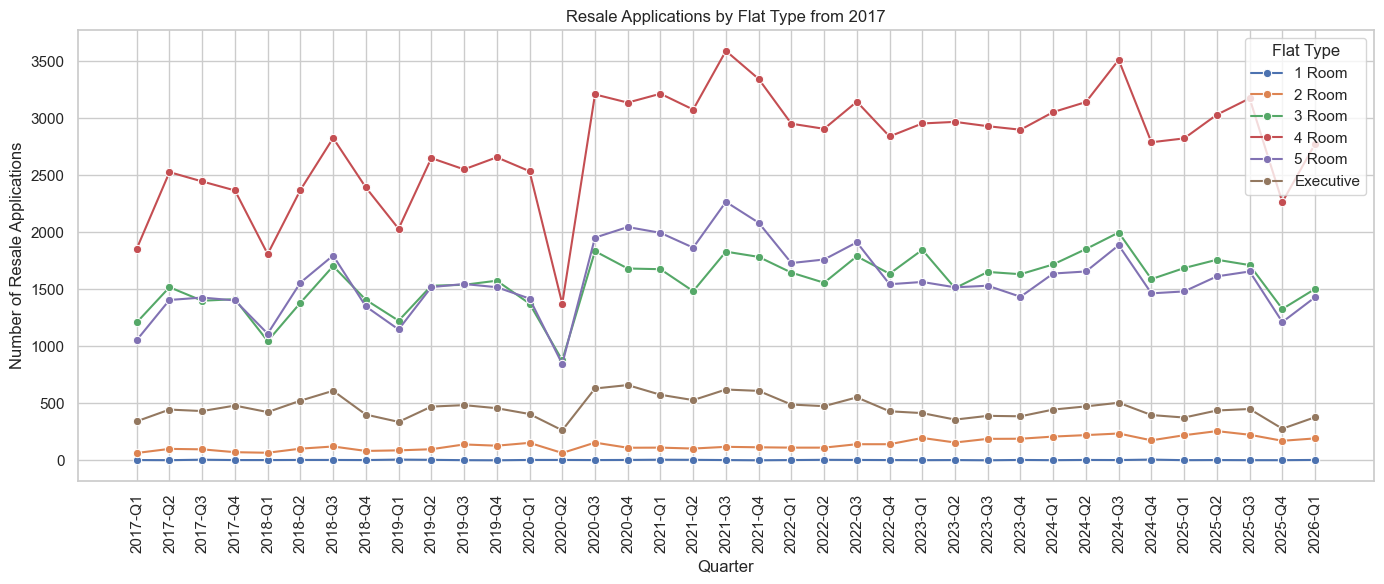

In [20]:
applications_recent = applications_clean[
    applications_clean["quarter"] >= "2017-Q1"
]

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=applications_recent,
    x="quarter",
    y="no_of_resale_applications",
    hue="flat_type",
    marker="o"
)

plt.title("Resale Applications by Flat Type from 2017")
plt.xlabel("Quarter")
plt.ylabel("Number of Resale Applications")
plt.xticks(rotation=90)
plt.legend(title="Flat Type")
plt.tight_layout()
plt.show()

**Code explanation:**

This code creates a line chart to show how resale applications changed over time by flat type.

First, I filtered `applications_clean` to keep only records from `2017-Q1` onwards. I did this because my main resale price dataset starts from 2017, so filtering the applications dataset to the same period makes the demand analysis more relevant and comparable.

The `plt.figure(figsize=(14, 6))` line sets the chart size in inches. The first number, `14`, is the width of the chart, and the second number, `6`, is the height. I used a wider chart because the x-axis contains many quarters, so it needs more horizontal space.

In `sns.lineplot()`, I used `quarter` on the x-axis and `no_of_resale_applications` on the y-axis. The `hue="flat_type"` part creates a separate line for each flat type, so I can compare demand trends across flat types. The `marker="o"` adds points to each quarter, making the changes easier to see.

The title and axis labels make the chart clear. `plt.xticks(rotation=90)` rotates the quarter labels vertically so they do not overlap. `plt.legend(title="Flat Type")` shows which line belongs to which flat type. `plt.tight_layout()` adjusts the spacing, and `plt.show()` displays the chart.

This chart helps me see which flat types have consistently higher resale demand and whether demand changes over time.

In [21]:
demand_price_correlation = (
    price_demand
    .groupby("flat_type")
    .apply(
        lambda group: group["no_of_resale_applications"].corr(group["median_resale_price"]),
        include_groups=False
    )
    .reset_index(name="correlation_between_demand_and_price")
    .sort_values("correlation_between_demand_and_price", ascending=False)
    .round(3)
)

demand_price_correlation

,flat_type,correlation_between_demand_and_price
1,2 Room,0.843
2,3 Room,0.457
3,4 Room,0.454
4,5 Room,0.156
5,Executive,-0.243
0,1 Room,-0.288


**Code explanation:**

This code calculates the correlation between resale demand and median resale price for each flat type. I used the merged `price_demand` dataset because it contains both `no_of_resale_applications` and `median_resale_price` for the same quarter and flat type.

First, I grouped the data by `flat_type` so that the correlation is calculated separately for each flat type. Inside `.apply()`, the `lambda group` function takes each flat type group one at a time.

For each flat type, `.corr()` compares `no_of_resale_applications` with `median_resale_price`. A positive correlation means demand and price tend to move in the same direction. A negative correlation means they tend to move in opposite directions. A value closer to 1 means a stronger positive relationship, while a value closer to -1 means a stronger negative relationship.

The `include_groups=False` part prevents the grouping column from being included inside the calculation. This keeps the correlation calculation focused only on the numerical columns being compared.

I used `.reset_index(name="correlation_between_demand_and_price")` to turn the result into a proper DataFrame and name the correlation column clearly. Then I sorted the results from highest to lowest correlation and rounded the values to 3 decimal places.

This helps me see which flat types show the strongest relationship between resale applications and resale prices.

Correlation measures how strongly two numerical variables move together. A positive correlation means resale applications and median resale price tend to increase together. A negative correlation means they tend to move in opposite directions. However, correlation does not prove that demand caused prices to increase.

### 9.1 Key Insights for Question 3

- 2 Room flats have the strongest positive relationship between resale applications and median resale prices, with a correlation of 0.843. This means demand and price tended to move strongly in the same direction for this flat type.

- 3 Room and 4 Room flats show moderate positive correlations of 0.457 and 0.454. This suggests demand may be related to price movement, but the relationship is not as strong as for 2 Room flats.

- 5 Room flats have a weak positive correlation of 0.156, while Executive and 1 Room flats have negative correlations. This shows that demand and price do not always move together for every flat type.

- Other factors such as location, flat size, remaining lease, buyer preferences, income eligibility, and available supply may also affect resale prices.

- A key limitation is that correlation does not prove causation. The results only show whether demand and price moved together, not whether demand directly caused price changes.

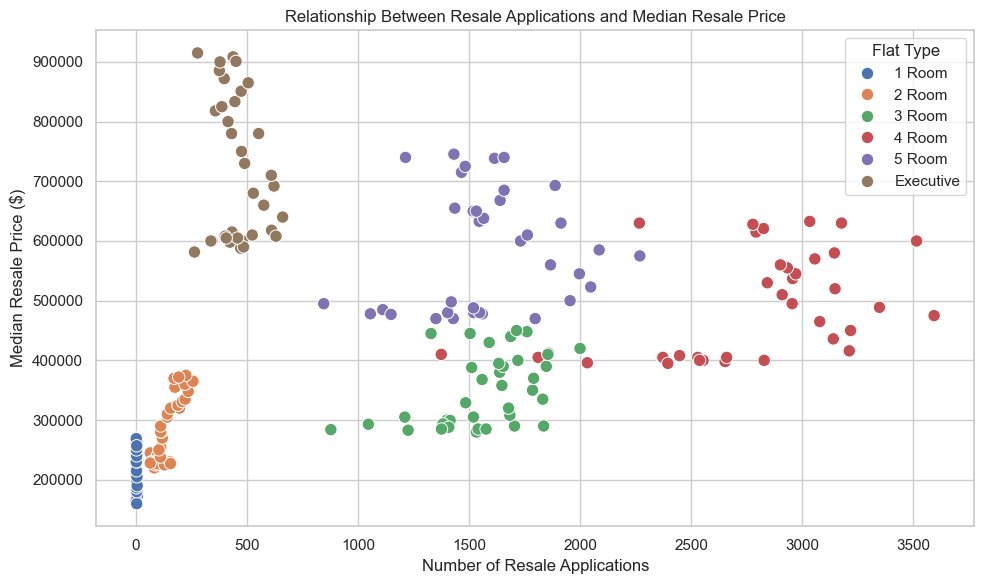

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=price_demand,
    x="no_of_resale_applications",
    y="median_resale_price",
    hue="flat_type",
    s=80
)

plt.title("Relationship Between Resale Applications and Median Resale Price")
plt.xlabel("Number of Resale Applications")
plt.ylabel("Median Resale Price ($)")
plt.legend(title="Flat Type")
plt.tight_layout()
plt.show()

**Code explanation:**

This code creates a scatter plot to show the relationship between resale applications and median resale price. It uses the `price_demand` dataset, which was created by merging quarterly resale price data with resale application data.

The `plt.figure(figsize=(10, 6))` line sets the chart size in inches. The first number, `10`, is the width, and the second number, `6`, is the height.

In `sns.scatterplot()`, the x-axis uses `no_of_resale_applications`, which represents resale demand. The y-axis uses `median_resale_price`, which represents the typical resale price for each flat type and quarter.

The `hue="flat_type"` part colours the points by flat type so I can compare different flat types in the same chart. The `s=80` controls the size of the points, making them easier to see.

The title and axis labels explain what the chart is showing. `plt.legend(title="Flat Type")` displays the flat type colour guide. `plt.tight_layout()` adjusts the spacing so labels are not cut off, and `plt.show()` displays the final chart.

This scatter plot helps me visually check whether higher resale applications are generally associated with higher median resale prices, and whether the pattern differs by flat type.

Each point in this scatter plot represents one flat type in one quarter. A quarter means a three-month period in a year. For example, 2017-Q1 refers to January to March 2017, while 2017-Q2 refers to April to June 2017.

The x-axis shows the number of resale applications for a flat type during that quarter. I used this as a simple way to represent resale demand. The y-axis shows the median resale price for the same flat type and quarter. The colours separate the different flat types.

I used this chart to check whether higher resale demand is linked to higher resale prices. From the chart and correlation result, 2 Room flats show the strongest positive relationship. However, I cannot say demand alone caused the price increase because other factors such as town, flat size, remaining lease, and supply can also affect resale prices.

## 10. Analysis Question 4: How Does HDB Flat Supply Differ Across Towns and Flat Types?

This section analyses the dwelling units dataset to examine HDB flat supply by town and flat type. Since the project focuses on the resale market, the analysis focuses mainly on sold units rather than rental units. Sold units are more relevant because they represent flats that may eventually enter the resale market.

In [23]:
print("Financial years:", dwelling_clean["financial_year"].min(), "to", dwelling_clean["financial_year"].max())

print("\nSold or rental categories:")
print(dwelling_clean["sold_or_rental"].unique())

print("\nFlat types:")
print(sorted(dwelling_clean["flat_type"].dropna().unique()))

print("\nMissing dwelling unit rows:")
display(dwelling_clean[dwelling_clean["no_of_dwelling_units"].isna()].head(10))

Financial years: 2008 to 2021

Sold or rental categories:
<StringArray>
['Rental Units', 'Sold Units']
Length: 2, dtype: str

Flat types:
['1 Room', '2 Room', '3 Room', '4 Room', '5 Room', 'Executive', 'Hudc', 'Studio Apartment']

Missing dwelling unit rows:


,financial_year,town_or_estate,flat_type,sold_or_rental,no_of_dwelling_units
4249,2020,Ang Mo Kio,Studio Apartment,Rental Units,NaN
4262,2020,Bedok,Studio Apartment,Rental Units,NaN
4275,2020,Bishan,Studio Apartment,Rental Units,NaN
4288,2020,Bukit Batok,Studio Apartment,Rental Units,NaN
4301,2020,Bukit Merah,Studio Apartment,Rental Units,NaN
4314,2020,Bukit Panjang,Studio Apartment,Rental Units,NaN
4327,2020,Bukit Timah,Studio Apartment,Rental Units,NaN
4340,2020,Central Area,Studio Apartment,Rental Units,NaN
4353,2020,Choa Chu Kang,Studio Apartment,Rental Units,NaN
4366,2020,Clementi,Studio Apartment,Rental Units,NaN


**Code explanation:**

This code checks the cleaned dwelling units dataset before using it for the supply analysis.

First, I printed the minimum and maximum `financial_year` values to see the time period covered by the dataset. This helps me understand the available supply data range before choosing the latest year for analysis.

Next, I printed the unique values in `sold_or_rental` to check whether the dataset separates sold units and rental units. This is important because my analysis focuses mainly on sold units, since they are more relevant to the resale market.

I also printed the unique `flat_type` values after dropping missing values with `.dropna()`. This helps me confirm what flat types are available in the supply dataset and whether the naming looks consistent after cleaning.

Finally, I displayed the first 10 rows where `no_of_dwelling_units` is missing. I did this to inspect the missing values instead of ignoring them immediately, because missing supply counts could affect the analysis if they appear in important towns or flat types. 
Some no_of_dwelling_units values became missing after I converted the column to numeric. This usually happens when the original CSV contains non-numeric entries, such as -, na, blank values, or suppressed values instead of actual numbers. Since Pandas cannot treat those as valid unit counts, pd.to_numeric(..., errors="coerce") converts them into NaN.

In [24]:
latest_supply_year = dwelling_clean["financial_year"].max()

sold_units_latest = dwelling_clean[
    (dwelling_clean["financial_year"] == latest_supply_year) &
    (dwelling_clean["sold_or_rental"] == "Sold Units") &
    (dwelling_clean["no_of_dwelling_units"].notna())
].copy()

print("Latest supply year:", latest_supply_year)
print("Sold units latest shape:", sold_units_latest.shape)

sold_units_latest.head()

Latest supply year: 2021
Sold units latest shape: (189, 5)


,financial_year,town_or_estate,flat_type,sold_or_rental,no_of_dwelling_units
4590,2021,Ang Mo Kio,1 Room,Sold Units,0.0
4592,2021,Ang Mo Kio,2 Room,Sold Units,952.0
4594,2021,Ang Mo Kio,3 Room,Sold Units,24443.0
4596,2021,Ang Mo Kio,4 Room,Sold Units,14704.0
4598,2021,Ang Mo Kio,5 Room,Sold Units,6150.0


**Code explanation:**

This code prepares the latest available sold-unit supply data for the supply analysis.

First, `latest_supply_year = dwelling_clean["financial_year"].max()` finds the most recent financial year in the dwelling units dataset. I used the latest year so the supply analysis reflects the most recent available HDB dwelling unit stock.

Next, I filtered `dwelling_clean` to keep only rows where the financial year equals `latest_supply_year`, the `sold_or_rental` category is `"Sold Units"`, and `no_of_dwelling_units` is not missing. This keeps the analysis focused on valid sold-unit records only.

I used `.notna()` to exclude rows with missing dwelling unit counts, because missing values cannot be added or compared meaningfully. I also used `.copy()` to create a separate DataFrame, so any later changes to `sold_units_latest` will not affect the original cleaned dataset.

The `print()` statements show the latest supply year and the shape of the filtered dataset. This helps me confirm how many rows and columns remain after filtering. Finally, `.head()` displays the first few rows so I can check that the filtered data looks correct.

In [25]:
supply_by_town = (
    sold_units_latest
    .groupby("town_or_estate")
    .agg(
        total_sold_units=("no_of_dwelling_units", "sum")
    )
    .sort_values("total_sold_units", ascending=False)
    .reset_index()
)

supply_by_town.head(10)

,town_or_estate,total_sold_units
0,Tampines,72750.0
1,Jurong West,72230.0
2,Sengkang,69113.0
3,Woodlands,66144.0
4,Yishun,63402.0
5,Bedok,60245.0
6,Hougang,56035.0
7,Punggol,53543.0
8,Choa Chu Kang,47647.0
9,Ang Mo Kio,47058.0


**Code explanation:**

This code summarises the latest sold HDB dwelling units by town or estate. It uses `sold_units_latest`, which already contains only the latest available year, sold units, and valid dwelling unit counts.

I grouped the data by `town_or_estate` so that each row represents one town instead of separate rows for different flat types. Then I used `.agg()` to calculate `total_sold_units` by summing `no_of_dwelling_units` for each town.

I sorted the results by `total_sold_units` in descending order so that the towns with the largest sold HDB flat supply appear first. Then I used `.reset_index()` to turn `town_or_estate` back into a normal column.

Finally, `.head(10)` displays the top 10 towns with the highest number of sold HDB dwelling units in the latest available supply year.

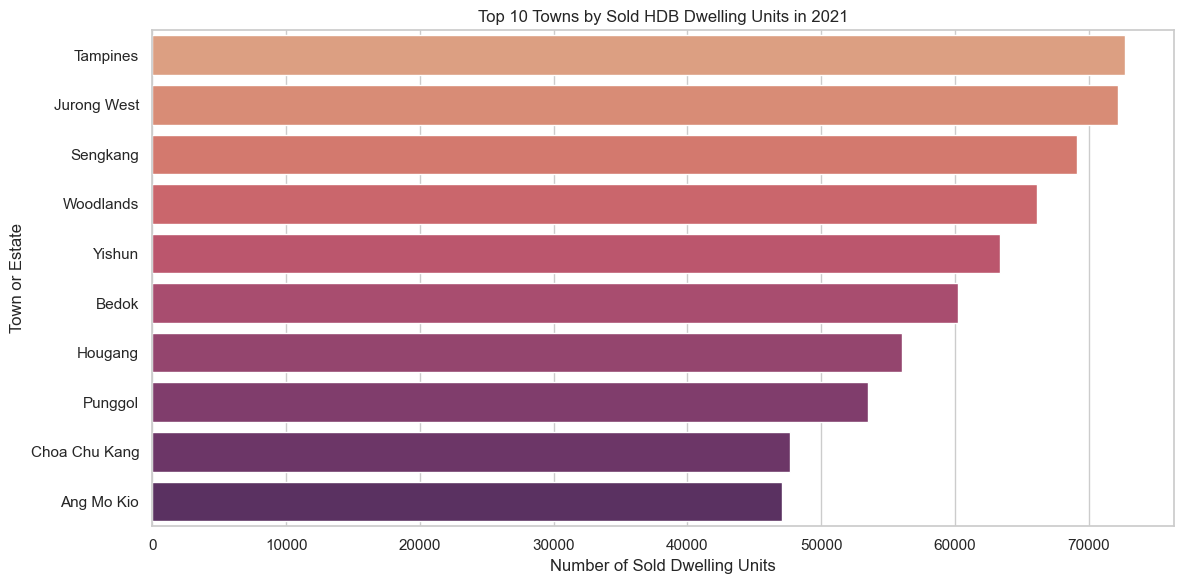

In [26]:
top_supply_towns = supply_by_town.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_supply_towns,
    x="total_sold_units",
    y="town_or_estate",
    hue="town_or_estate",
    palette="flare",
    legend=False
)

plt.title(f"Top 10 Towns by Sold HDB Dwelling Units in {latest_supply_year}")
plt.xlabel("Number of Sold Dwelling Units")
plt.ylabel("Town or Estate")
plt.tight_layout()
plt.show()

**Code explanation:**

This code creates a bar chart showing the top 10 towns with the highest number of sold HDB dwelling units in the latest available supply year.

First, `top_supply_towns = supply_by_town.head(10)` selects the first 10 rows from `supply_by_town`. Since `supply_by_town` was already sorted from highest to lowest total sold units, this gives the top 10 towns.

The `plt.figure(figsize=(12, 6))` line sets the chart size in inches. The first number, `12`, is the width, and the second number, `6`, is the height.

In `sns.barplot()`, the x-axis uses `total_sold_units`, and the y-axis uses `town_or_estate`. I used `hue="town_or_estate"` so each town has its own colour, and `palette="flare"` controls the colour theme. I set `legend=False` because the town names are already shown on the y-axis, so a legend would repeat the same information.

The chart title uses an f-string, `f"..."`, so the value of `latest_supply_year` is inserted automatically into the title. The x-axis and y-axis labels explain what the chart is showing.

Finally, `plt.tight_layout()` adjusts the spacing so labels are not cut off, and `plt.show()` displays the chart.

In [27]:
supply_by_flat_type = (
    sold_units_latest
    .groupby("flat_type")
    .agg(
        total_sold_units=("no_of_dwelling_units", "sum")
    )
    .sort_values("total_sold_units", ascending=False)
    .reset_index()
)

supply_by_flat_type

,flat_type,total_sold_units
0,4 Room,433178.0
1,5 Room,247740.0
2,3 Room,245692.0
3,Executive,65116.0
4,2 Room,32011.0
5,Studio Apartment,8708.0
6,1 Room,254.0


**Code explanation:**

This code summarises the latest sold HDB dwelling units by flat type. It uses `sold_units_latest`, which already contains only sold-unit records from the latest available supply year.

I grouped the data by `flat_type` so that each row represents one flat type, such as 3 Room, 4 Room, 5 Room, or Executive. Then I used `.agg()` to calculate `total_sold_units` by summing `no_of_dwelling_units` for each flat type.

I sorted the results by `total_sold_units` in descending order so the flat types with the largest sold HDB supply appear first. I also used `.reset_index()` to turn `flat_type` back into a normal column.

This table helps show which flat types make up the largest share of HDB sold flat supply in the latest available year.

The last line `supply_by_flat_type` is just to display the DataFrame in the notebook so I can view the summary table. It does not change the data.

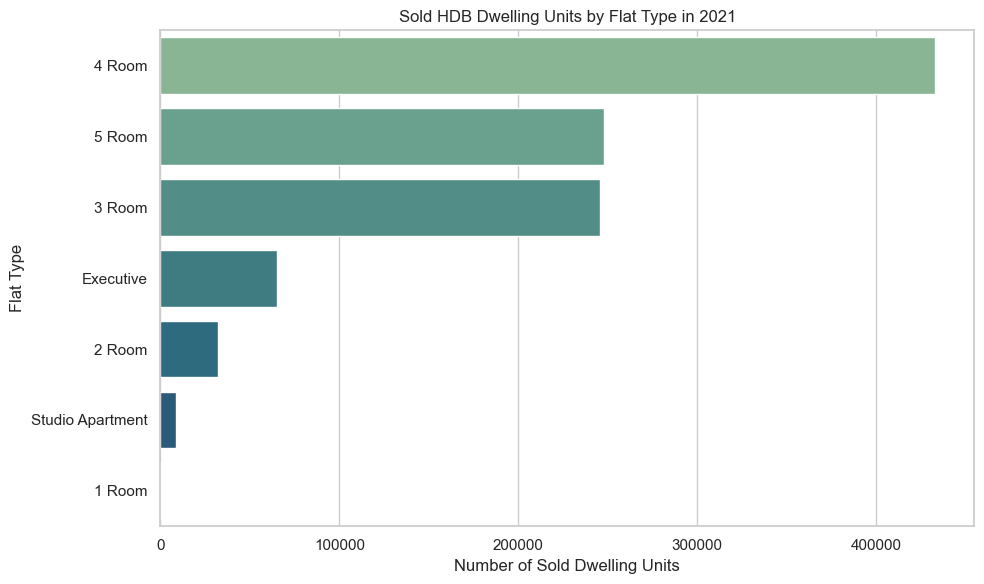

In [28]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=supply_by_flat_type,
    x="total_sold_units",
    y="flat_type",
    hue="flat_type",
    palette="crest",
    legend=False
)

plt.title(f"Sold HDB Dwelling Units by Flat Type in {latest_supply_year}")
plt.xlabel("Number of Sold Dwelling Units")
plt.ylabel("Flat Type")
plt.tight_layout()
plt.show()

**Code explanation:**

This code creates a bar chart showing the number of sold HDB dwelling units by flat type in the latest available supply year.

The `plt.figure(figsize=(10, 6))` line sets the chart size in inches. The first number, `10`, is the width, and the second number, `6`, is the height.

In `sns.barplot()`, I used `supply_by_flat_type` as the data source. The x-axis shows `total_sold_units`, and the y-axis shows `flat_type`, so each bar represents the total sold dwelling units for one flat type.

I used `hue="flat_type"` so each flat type has its own colour, and `palette="crest"` controls the colour theme. I set `legend=False` because the flat types are already labelled on the y-axis, so a separate legend would repeat the same information.

The chart title uses an f-string, so `latest_supply_year` is inserted automatically into the title. The x-axis and y-axis labels make the chart easier to understand.

Finally, `plt.tight_layout()` adjusts the spacing so labels are not cut off, and `plt.show()` displays the chart.

This section filters the dwelling units dataset to the latest available financial year and keeps only sold units because sold HDB flats are more relevant to the resale market than rental units. The data is then grouped by town and flat type to compare where HDB flat supply is concentrated.

### 10.1 Key Insights for Question 4

- The latest available year in the dwelling units dataset is 2021, so the supply analysis is based on 2021 data.

- The towns with the highest number of sold HDB dwelling units include Tampines, Jurong West, Sengkang, Woodlands, Yishun, Bedok, Hougang, Punggol, Choa Chu Kang, and Ang Mo Kio. These are mostly large residential towns, so higher supply is expected.

- By flat type, 4 Room flats have the highest number of sold dwelling units. This suggests that 4 Room flats form a major part of Singapore’s HDB housing stock.

- 3 Room and 5 Room flats also have high supply, while 1 Room, 2 Room, Studio Apartment, and Executive flats have much lower supply.

- Supply helps explain possible resale price pressure. If demand is high but available supply is limited, prices may face stronger upward pressure.

- However, supply alone does not fully explain resale prices. Other factors such as location, flat age, remaining lease, MRT access, amenities, and buyer preferences also matter.

- A limitation is that supply data only goes up to 2021, while resale price data goes up to 2026. Therefore, the supply analysis should be treated as background context, not a direct explanation for every recent price change.

### 10.2 Comparing Town Supply with 2021 Resale Price per Square Metre

To make the supply analysis more meaningful, the latest available supply data is compared with resale price per square metre in the same year. Since the dwelling units dataset ends in 2021, the resale price data is also filtered to 2021 for a fairer comparison.

In [29]:
resale_2021_town_prices = (
    resale_clean[resale_clean["year"] == latest_supply_year]
    .groupby("town")
    .agg(
        transaction_count=("resale_price", "count"),
        median_resale_price=("resale_price", "median"),
        median_price_per_sqm=("price_per_sqm", "median")
    )
    .reset_index()
)

supply_price_2021 = resale_2021_town_prices.merge(
    supply_by_town,
    left_on="town",
    right_on="town_or_estate",
    how="inner"
)

supply_price_2021 = supply_price_2021[
    ["town", "transaction_count", "total_sold_units", "median_resale_price", "median_price_per_sqm"]
].sort_values("median_price_per_sqm", ascending=False)

supply_price_2021.head(10)

,town,transaction_count,total_sold_units,median_resale_price,median_price_per_sqm
7,Central Area,261,8884.0,665000.0,7881.355932
18,Queenstown,987,34027.0,705000.0,7654.311111
4,Bukit Merah,1173,44960.0,630000.0,6504.347826
6,Bukit Timah,82,2554.0,703300.0,6485.398860
2,Bishan,570,19263.0,640444.0,6015.625000
15,Marine Parade,204,6532.0,488444.0,5953.201970
14,Kallang/Whampoa,882,33729.0,538000.0,5714.285714
9,Clementi,672,25771.0,531500.0,5498.268657
17,Punggol,2742,53543.0,500000.0,5403.024452
23,Toa Payoh,916,38054.0,468000.0,5172.082604


**Code explanation:**

This code compares town-level HDB supply with resale price per square metre in the same year. Since the dwelling units dataset only goes up to `latest_supply_year`, I filtered the resale price dataset to that same year so the comparison is fairer.

First, I created `resale_2021_town_prices` by filtering `resale_clean` to only rows where `year` equals `latest_supply_year`. Then I grouped the filtered resale data by `town` so each row represents one town.

The `.agg()` aggregate function tells Pandas what summary values to calculate for each town group. In this case, I calculated `transaction_count` by counting resale price records, `median_resale_price` by taking the median resale price, and `median_price_per_sqm` by taking the median price per square metre.

I used `.reset_index()` after grouping because `town` becomes an index after `groupby()`. Resetting the index turns `town` back into a normal column, which makes it easier to merge and display later.

Next, I merged `resale_2021_town_prices` with `supply_by_town`. I used `left_on="town"` and `right_on="town_or_estate"` because the same town information has different column names in the two datasets. I used `how="inner"` so only towns found in both datasets are kept.

After merging, I selected only the columns needed for comparison: town, transaction count, total sold units, median resale price, and median price per square metre. I sorted the result by `median_price_per_sqm` in descending order to show towns with the highest size-adjusted prices first.

Finally, `.head(10)` displays the top 10 towns by median price per square metre for the supply-price comparison.

This merge compares town-level supply and town-level resale prices using the same year, 2021. I filtered resale prices to 2021 because the supply dataset only goes up to 2021. This makes the comparison more consistent.

The 2021 comparison shows that towns with the highest price per square metre are not always the towns with the largest HDB supply. For example, Central Area has only 8,884 sold dwelling units but has the highest median price per square metre at about $7,881.36. Bukit Timah also has a small supply of 2,554 sold dwelling units but a high median price per square metre of about $6,485.40.

In contrast, Punggol has a much larger supply of 53,543 sold dwelling units, but its median price per square metre is lower than Central Area, Queenstown, Bukit Merah, and Bukit Timah. This suggests that location and town characteristics may strongly influence resale price pressure, not just the number of available HDB units.

Queenstown and Bukit Merah are notable because they have both relatively large supply and high price per square metre. This may suggest that strong location attractiveness and demand can keep prices high even when the town has many sold HDB units.

Overall, this comparison suggests that HDB resale price pressure is affected by both supply and location-based demand. Supply is useful context, but it does not fully explain price differences between towns.

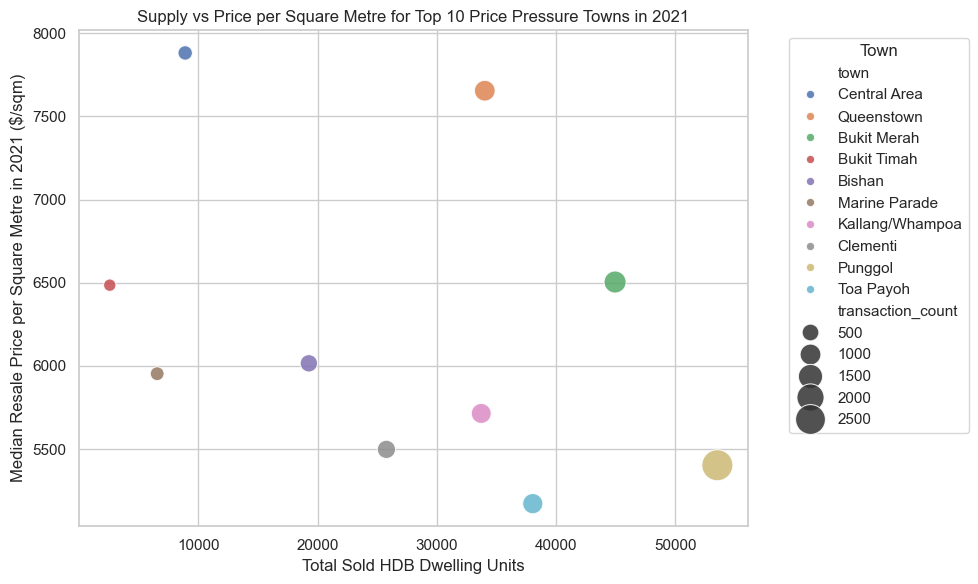

In [30]:
top_supply_price_towns = supply_price_2021.head(10)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=top_supply_price_towns,
    x="total_sold_units",
    y="median_price_per_sqm",
    size="transaction_count",
    hue="town",
    sizes=(80, 500),
    alpha=0.85
)

plt.title("Supply vs Price per Square Metre for Top 10 Price Pressure Towns in 2021")
plt.xlabel("Total Sold HDB Dwelling Units")
plt.ylabel("Median Resale Price per Square Metre in 2021 ($/sqm)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="Town")
plt.tight_layout()
plt.show()

**Code explanation:**

This code creates a scatter plot to compare HDB sold-unit supply with median resale price per square metre for the top 10 price pressure towns in 2021.

First, `top_supply_price_towns = supply_price_2021.head(10)` selects the top 10 towns from `supply_price_2021`. Since `supply_price_2021` was already sorted by `median_price_per_sqm` from highest to lowest, these are the top 10 towns by size-adjusted resale price.

The `plt.figure(figsize=(10, 6))` line sets the chart size in inches. The first number, `10`, is the width, and the second number, `6`, is the height.

In `sns.scatterplot()`, the x-axis shows `total_sold_units`, which represents HDB sold-unit supply. The y-axis shows `median_price_per_sqm`, which represents price pressure after adjusting for flat size.

The `size="transaction_count"` part makes the points larger or smaller based on the number of resale transactions in that town. The `hue="town"` part gives each town a different colour. The `sizes=(80, 500)` setting controls the minimum and maximum point sizes, and `alpha=0.85` makes the points slightly transparent so the chart looks clearer.

The chart title and axis labels explain what is being compared. The `plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="Town")` line moves the legend outside the chart area on the right, so it does not cover the data points.

Finally, `plt.tight_layout()` adjusts the spacing so labels and the outside legend fit properly, and `plt.show()` displays the chart.

This chart helps me compare whether towns with higher supply also have lower or higher price per square metre. It shows that supply alone does not fully explain price pressure, because some towns can have relatively high supply but still high price per square metre.

Let me use Queenstown as an example. This orange circle represents Queenstown. Its x-position is around 34,000 sold HDB dwelling units, so that shows the supply level in 2021. Its y-position is around $7,650 per sqm, so that shows the median resale price per square metre in 2021. The circle is also quite large, which means Queenstown had a relatively high number of resale transactions compared with some other towns in this chart.

Each circle in this scatter plot represents one town. The x-axis shows the total number of sold HDB dwelling units in that town in 2021. This represents the stock of sold HDB flats, not the number of resale transactions. 

The y-axis shows the median resale price per square metre in 2021. I used price per square metre because it is fairer than comparing total resale price only, since flats in different towns may have different average sizes.

The size of each circle represents the number of resale transactions in that town in 2021. This means transaction count only controls the circle size. It is not the same as total sold dwelling units, and it is not the y-axis.

This chart shows that towns with lower supply, such as Central Area and Bukit Timah, can still have high price per square metre. This suggests that supply is not the only factor affecting price pressure. Location, estate maturity, accessibility, and buyer preference also matter.

### 10.3 Official Median Price Dataset Validation

The official median resale price dataset is used to compare official quarterly median prices with the median prices calculated from the transaction-level resale dataset. This helps check whether the transaction-level analysis is consistent with the official summary dataset.

In [31]:
common_quarters = sorted(set(resale_clean["quarter"]).intersection(set(median_clean["quarter"])))
latest_common_quarter = common_quarters[-1]

official_latest = median_clean[
    (median_clean["quarter"] == latest_common_quarter) &
    (median_clean["price"].notna())
].copy()

calculated_latest = (
    resale_clean[resale_clean["quarter"] == latest_common_quarter]
    .groupby(["town", "flat_type"])
    .agg(
        calculated_median_price=("resale_price", "median"),
        transaction_count=("resale_price", "count")
    )
    .reset_index()
)

median_validation = official_latest.merge(
    calculated_latest,
    on=["town", "flat_type"],
    how="inner"
)

median_validation["price_difference"] = (
    median_validation["calculated_median_price"] - median_validation["price"]
)

median_validation.head(10)

,quarter,town,flat_type,price,calculated_median_price,transaction_count,price_difference
0,2026-Q1,Ang Mo Kio,3 Room,441800.0,441833.0,86,33.0
1,2026-Q1,Ang Mo Kio,4 Room,630000.0,630000.0,83,0.0
2,2026-Q1,Bedok,3 Room,425500.0,426000.0,119,500.0
3,2026-Q1,Bedok,4 Room,588000.0,594000.0,120,6000.0
4,2026-Q1,Bedok,5 Room,809000.0,809000.0,50,0.0
5,2026-Q1,Bishan,4 Room,805000.0,805000.0,44,0.0
6,2026-Q1,Bishan,5 Room,970000.0,970000.0,21,0.0
7,2026-Q1,Bukit Batok,2 Room,382000.0,382000.0,27,0.0
8,2026-Q1,Bukit Batok,3 Room,410000.0,410000.0,78,0.0
9,2026-Q1,Bukit Batok,4 Room,649000.0,650000.0,137,1000.0


**Code explanation:**

This code compares the official median resale price dataset with the median prices that I calculated from the transaction dataset. I used this as a validation step to check whether my own calculations are reasonable.

First, `common_quarters` finds the quarters that appear in both `resale_clean` and `median_clean`. I used `set(...).intersection(...)` to keep only quarters that exist in both datasets, then `sorted()` arranges them in order. `latest_common_quarter = common_quarters[-1]` selects the latest quarter that both datasets share.

Next, I created `official_latest` by filtering `median_clean` to the latest common quarter and keeping only rows where the official `price` is not missing. I used `.copy()` so this filtered dataset is separate from the original cleaned median dataset.

Then I created `calculated_latest` from `resale_clean` for the same quarter. I grouped the transaction data by `town` and `flat_type`, then used `.agg()` to calculate my own `calculated_median_price` and `transaction_count` for each town and flat type. I used `.reset_index()` so `town` and `flat_type` become normal columns again.

After that, I merged the official median prices with my calculated median prices using `town` and `flat_type`, because these are the common columns in both datasets. I used `how="inner"` so only matching town and flat type combinations are compared.

Finally, I created `price_difference` by subtracting the official median price from my calculated median price. If the difference is small, it suggests my calculation is close to the official figures. `median_validation.head(10)` displays the first 10 rows so I can inspect the validation results.

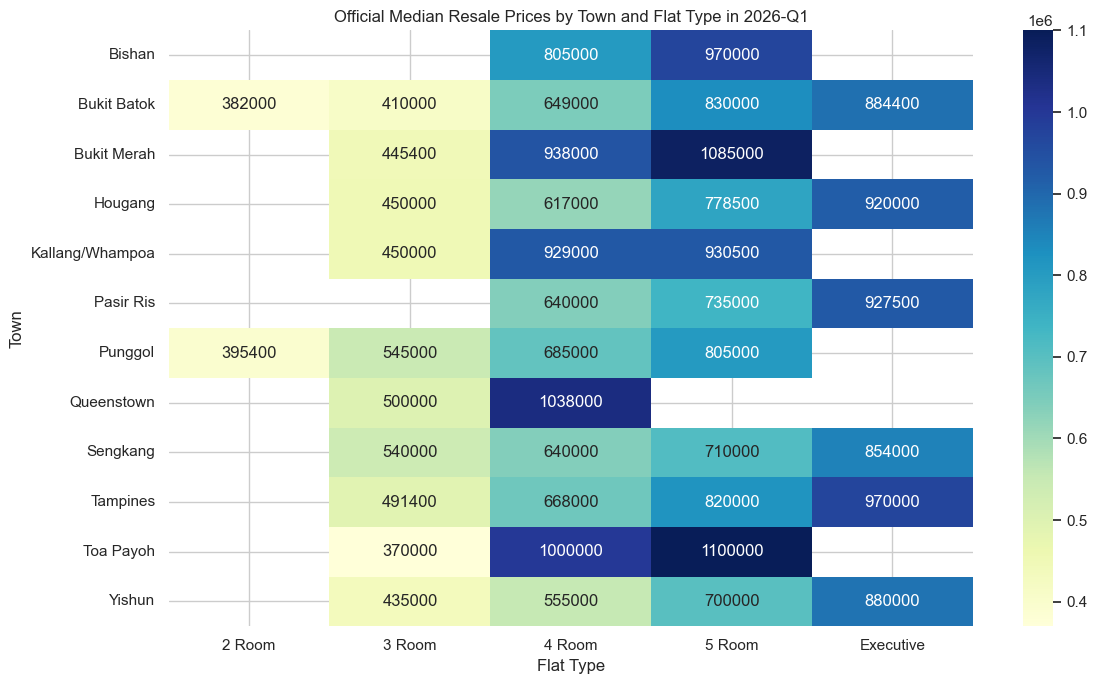

In [32]:
top_official_towns = (
    official_latest.groupby("town")["price"]
    .median()
    .sort_values(ascending=False)
    .head(12)
    .index
)

heatmap_data = official_latest[
    official_latest["town"].isin(top_official_towns)
].pivot_table(
    index="town",
    columns="flat_type",
    values="price",
    aggfunc="median"
)

plt.figure(figsize=(12, 7))
sns.heatmap(heatmap_data, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title(f"Official Median Resale Prices by Town and Flat Type in {latest_common_quarter}")
plt.xlabel("Flat Type")
plt.ylabel("Town")
plt.tight_layout()
plt.show()

**Code explanation:**

This code creates a heatmap using the official median resale price dataset for the latest common quarter. The purpose is to compare official median prices across towns and flat types in a more visual way.

First, I created `top_official_towns` by grouping `official_latest` by `town` and taking the median official `price` for each town. Then I sorted the towns from highest to lowest median price, selected the top 12 towns using `.head(12)`, and used `.index` to store only the town names.

Next, I filtered `official_latest` to keep only rows where the town is in `top_official_towns`. I used `.isin(top_official_towns)` for this filtering.

Then I used `.pivot_table()` to reshape the data into a heatmap format. The rows are towns, the columns are flat types, and the values are official median prices. I used `aggfunc="median"` in case there are repeated town and flat type combinations, so Pandas knows how to summarise them.

The `plt.figure(figsize=(12, 7))` line sets the chart size in inches. The first number, `12`, is the width, and the second number, `7`, is the height.

In `sns.heatmap()`, `annot=True` displays the price values inside the cells, `fmt=".0f"` shows the values without decimal places, and `cmap="YlGnBu"` sets the heatmap colour theme. Darker colours generally represent higher median resale prices.

The chart title uses an f-string so `latest_common_quarter` is inserted automatically. The x-axis label shows flat type, the y-axis label shows town, `plt.tight_layout()` adjusts spacing, and `plt.show()` displays the final heatmap.

This heatmap helps me quickly identify which town and flat type combinations have higher official median resale prices.

The official median resale price dataset is used here to check whether my transaction-level analysis is consistent with HDB's official summary data.

This is useful because the resale prices dataset contains individual transactions, while the official median price dataset already summarises prices by quarter, town, and flat type. If both datasets show similar high-price towns, it gives more confidence that my findings are reasonable.

The heatmap shows that towns such as Central Area, Queenstown, Bukit Merah, Bukit Timah, and Bishan continue to appear as higher-price areas. It also shows that larger flat types usually have higher median prices.

One limitation is that some official median prices are missing when there are too few transactions for a specific town, flat type, and quarter.

## 11. Overall Conclusion and Recommendations

- HDB resale prices increased across all flat types from 2017 to 2026.

- In percentage terms, 2 Room flats had the strongest growth. In absolute dollar terms, Multi Generation flats had the largest increase.

- By town, stronger price pressure based on price per square metre was found in Central Area, Queenstown, Bukit Merah, Bukit Timah, and Bishan.

- Price per square metre is useful because it gives a fairer comparison between towns with different flat sizes.

- The demand analysis showed that 2 Room flats had the strongest positive relationship between resale applications and median resale prices.

- However, demand alone does not fully explain resale price changes because the relationship was weaker or negative for some flat types.

- The supply analysis showed that towns with more sold HDB units do not always have lower prices, so supply alone also does not fully explain price pressure.

- Other important factors include location, estate maturity, accessibility, flat type, remaining lease, and buyer preferences.

- For young buyers, the recommendation is to compare resale flats using more than just total price. They should also consider price per square metre, remaining lease, town, flat type, and long-term demand in the area.

## 12. Limitations and Future Improvements

- The resale price dataset only shows completed transactions. It does not show unsuccessful offers, buyer income, seller expectations, or why buyers chose a particular flat.

- Because of this, the analysis can identify price patterns, but it cannot fully explain buyer behaviour.

- The dwelling units dataset only goes up to financial year 2021, while the resale price dataset goes up to 2026.

- This means the supply analysis is useful as background context, but it cannot fully explain resale price changes from 2022 to 2026.

- The analysis does not directly include factors such as MRT distance, distance to the city centre, school proximity, estate maturity, renovation condition, or interest rates.

- These missing factors may also affect resale prices, so the results should be interpreted carefully.

- Future improvements could include adding geospatial data, MRT station distance, remaining lease calculations, household income data, and economic indicators.

- A more advanced version of this project could build a predictive model to estimate resale prices using town, flat type, floor area, remaining lease, and storey range.

## 13. Key Python Techniques Used

- `pd.read_csv()` was used to load the CSV files into Pandas DataFrames.

- `.head()`, `.shape`, `.info()`, `.isna().sum()`, and `.duplicated().sum()` were used for initial data inspection.

- `pd.to_datetime()` was used to convert the resale `month` column from text into a date format.

- `.dt.year` and `.dt.quarter` were used to create year and quarter columns for time-based analysis.

- `pd.to_numeric()` was used to convert text columns, such as official median price and dwelling unit counts, into numeric values.

- `.groupby()` and `.agg()` were used to calculate summary statistics by year, quarter, town, and flat type.

- NumPy was used to calculate standard deviation for resale prices.

- `.merge()` was used to combine datasets using common columns such as `quarter`, `flat_type`, and `town`.

- Seaborn and Matplotlib were used to create the visualisations, including line charts, bar charts, box plots, scatter plots, and heatmaps.